# 02 — Preparação dos dados: ARES

**CRISP-DM, fase 3** · corresponde à seção **§5.1** de `docs/DOCUMENTACAO.md`

Passo a passo:
1. Notas: sanitização e **validação cruzada** (descoberta da regra “a nota oficial não conta a Q9”)
2. Exclusão das contas que não são de alunos (lista dos autores do dataset)
3. Limpeza do log xAPI: duplicadas, nulos, datas, JSON, atores e páginas
4. Separação por contexto (aprendizagem × provas × questionários)
5. Categorias de atividade com significado pedagógico
6. Atributos por aluno: interações, sessões, dias ativos, tempo, evolução
7. Outliers
8. **Conferência com o arquivo oficial** `data/processed/ares_alunos.csv`

In [1]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)
EXT = "http://mintly.kibi.group/contextExtension/"

Projeto: C:\Users\Usuário\Desktop\Datasets-Beready\Datasets-Beready


## 1. Notas do pré e do pós-teste

### 1.1 Leitura e perfil

In [2]:
resp = {t: pd.read_excel(C.ARES_RAW / f"{t}_test_response.xlsx") for t in ("pre", "post")}
nota = {t: pd.read_excel(C.ARES_RAW / f"{t}_test_score.xlsx") for t in ("pre", "post")}
for t in ("pre", "post"):
    print(f"{t}_test_response: {resp[t].shape} | nulos: {resp[t].isna().sum().to_dict()} | duplicadas: {resp[t].duplicated().sum()}")
    print(f"{t}_test_score   : {nota[t].shape} | nulos: {nota[t].isna().sum().to_dict()} | duplicadas: {nota[t].duplicated().sum()}")

pre_test_response: (2520, 6) | nulos: {'id': 0, 'user_id': 0, 'prompt': 0, 'response': 184, 'timestamp': 0, 'correct': 0} | duplicadas: 0
pre_test_score   : (210, 2) | nulos: {'user_id': 0, 'score': 0} | duplicadas: 0
post_test_response: (1980, 6) | nulos: {'id': 0, 'user_id': 12, 'prompt': 0, 'response': 82, 'timestamp': 0, 'correct': 0} | duplicadas: 0
post_test_score   : (164, 2) | nulos: {'user_id': 0, 'score': 0} | duplicadas: 0


### 1.2 Sanitização

- Linhas de resposta **sem `user_id`** não podem ser atribuídas a ninguém e são removidas (12 no pós-teste).
- Respostas **em branco** (`response` vazio) são **mantidas como erro**: o aluno viu a questão e não respondeu (`correct = f`).
- `correct` é padronizado (sem espaços, minúsculo) e validado em {t, f}.
- Nas notas: espaços removidos do `user_id`, verificação de ids duplicados e de notas fora de 0–11.

In [3]:
for t in ("pre", "post"):
    r = resp[t]
    n0 = len(r)
    r = r.dropna(subset=["user_id"]).drop_duplicates()
    r["user_id"] = r["user_id"].str.strip()
    r["correct"] = r["correct"].str.strip().str.lower()
    r["acertou"] = r["correct"].eq("t")
    resp[t] = r
    s = nota[t]
    s["user_id"] = s["user_id"].str.strip()
    print(f"[{t}] linhas sem user_id removidas: {n0 - len(r)} | respostas em branco (contam como erro): {r['response'].isna().sum()}"
          f" | correct fora de t/f: {(~r['correct'].isin(['t', 'f'])).sum()}"
          f" | user_id duplicado na nota: {s['user_id'].duplicated().sum()}"
          f" | notas fora de 0–11: {(~s['score'].between(0, 11)).sum()}"
          f" | questões por aluno: {r.groupby('user_id').size().value_counts().to_dict()}")

[pre] linhas sem user_id removidas: 0 | respostas em branco (contam como erro): 184 | correct fora de t/f: 0 | user_id duplicado na nota: 0 | notas fora de 0–11: 0 | questões por aluno: {12: 210}
[post] linhas sem user_id removidas: 12 | respostas em branco (contam como erro): 82 | correct fora de t/f: 0 | user_id duplicado na nota: 0 | notas fora de 0–11: 0 | questões por aluno: {12: 164}


### 1.3 Validação cruzada: a nota oficial é mesmo a soma dos acertos?

Somando os acertos das 12 questões e comparando com a nota oficial:

In [4]:
for t in ("pre", "post"):
    soma12 = resp[t].groupby("user_id")["acertou"].sum()
    oficial = nota[t].set_index("user_id")["score"]
    print(f"[{t}] nota = soma das 12 questões em {(soma12.reindex(oficial.index) == oficial).mean():.1%} dos alunos")
    diff = (oficial - soma12.reindex(oficial.index)).value_counts().to_dict()
    print(f"      diferença (oficial − soma12): {diff}")

[pre] nota = soma das 12 questões em 71.0% dos alunos
      diferença (oficial − soma12): {0: 149, -1: 61}
[post] nota = soma das 12 questões em 72.6% dos alunos
      diferença (oficial − soma12): {0: 119, -1: 45}


A diferença é sempre **0 ou −1**: uma das questões não entra na nota. Testando a exclusão de **cada** questão:

In [5]:
for t in ("pre", "post"):
    oficial = nota[t].set_index("user_id")["score"]
    r = resp[t]
    res = {}
    for q in sorted(r["prompt"].unique()):
        recalc = r[r["prompt"] != q].groupby("user_id")["acertou"].sum()
        res[q] = (recalc.reindex(oficial.index) == oficial).mean()
    s = pd.Series(res).sort_values(ascending=False)
    print(f"[{t}] concordância ao excluir cada questão:")
    print(s.map("{:.1%}".format).head(4).to_string(), "\n")

[pre] concordância ao excluir cada questão:
PreTestQ9       100.0%
PreTestQ10-2     61.0%
PreTestQ10-3     59.0%
PreTestQ8        56.7% 

[post] concordância ao excluir cada questão:
PostTestQ9       100.0%
PostTestQ10-2     64.0%
PostTestQ10-3     62.8%
PostTestQ8        62.2% 



✅ **Excluindo a Q9, a nota recalculada bate em 100% dos alunos**, nos dois testes. Por isso a nota oficial vai de 0 a 11, e não de 0 a 12.

(Isso também explica parte da diferença com o notebook antigo `Test2_8y3zp.ipynb`, que somava as 12 questões; ver o notebook 04.)

## 2. Exclusão de contas que não são de alunos

A lista vem do notebook dos **próprios autores do dataset** (`data/raw/ares/script/02_data_user_removal.ipynb`):

In [6]:
from ares_01_prepare import REMOVER, IDS_REMOVER
for motivo, ids in REMOVER.items():
    print(f"{motivo:20s} ({len(ids):2d}): {', '.join(ids)}")
print("Total de ids a remover:", len(IDS_REMOVER))

conta_teste          ( 1): EKEi
professor            ( 7): 82PN, 0jWs, W2Fl, FUs4, VNzA, P5ze, OVhL
conta_nao_usada      (14): ZznH, eVKy, zRSE, ImNX, kxxe, am1M, x5ot, Fl9u, 9FEW, wU4m, JmnJ, ow1W, Yp1o, 48jO
sem_submissao        (15): eKlW, WUkv, zkmh, m25O, F1aL, wgEB, 5AAK, XfM3, R49T, NBrF, zZSe, ggi5, wAr0, wRnG, keoO
sem_consentimento    (12): gxjp, K4b1, ntzG, aNxJ, lOkr, QUU6, ewww, QWJu, nC8b, YD86, s3v8, g1gg
Total de ids a remover: 49


In [7]:
notas = {}
for t, col in (("pre", "nota_pre"), ("post", "nota_pos")):
    s = nota[t].drop_duplicates("user_id")
    antes = len(s)
    s = s[~s["user_id"].isin(IDS_REMOVER)]
    print(f"[{t}] alunos: {antes} → removidos pela lista: {antes - len(s)} → válidos: {len(s)}")
    notas[t] = s.rename(columns={"score": col})
mot = pd.read_excel(C.ARES_RAW / "pre_motivation_score.xlsx").drop_duplicates("user_id")
mot = mot[~mot["user_id"].isin(IDS_REMOVER)]
alunos = notas["pre"].merge(notas["post"], on="user_id", how="outer").merge(mot, on="user_id", how="left")
print("Alunos válidos (com pré ou pós):", len(alunos))
print("Com pré e pós:", alunos[["nota_pre", "nota_pos"]].notna().all(axis=1).sum())

[pre] alunos: 210 → removidos pela lista: 25 → válidos: 185
[post] alunos: 164 → removidos pela lista: 16 → válidos: 148
Alunos válidos (com pré ou pós): 192
Com pré e pós: 141


## 3. Limpeza do log de interações (xAPI)

Cada passo é registrado com quantas linhas removeu, formando a tabela da §5.1.1.

In [8]:
x = pd.read_excel(C.ARES_DIR / "preprocessed" / "xapi_statement_student.xlsx")
passos = [("leitura de preprocessed/xapi_statement_student.xlsx", 0, len(x))]

# 1) duplicadas exatas
n = len(x); x = x.drop_duplicates(); passos.append(("remover duplicadas exatas", n - len(x), len(x)))
# 2) nulos em campos obrigatórios
n = len(x); x = x.dropna(subset=["actor", "verb", "timestamp"]); passos.append(("remover nulos em actor/verb/timestamp", n - len(x), len(x)))
# 3) datas válidas dentro do período do estudo
x["timestamp"] = pd.to_datetime(x["timestamp"], utc=True, format="mixed", errors="coerce")
n = len(x)
x = x[x["timestamp"].between(pd.Timestamp("2024-09-01", tz="UTC"), pd.Timestamp("2025-03-31", tz="UTC"))]
passos.append(("remover timestamp inválido/fora do período", n - len(x), len(x)))

# 4) JSON do contexto
def parse(c):
    try:
        return {k.replace(EXT, ""): v for k, v in json.loads(c).get("extensions", {}).items()}
    except (TypeError, ValueError):
        return None
ctx = x["context"].apply(parse)
n = len(x); x = x[ctx.notna()]; ctx = ctx[ctx.notna()]
passos.append(("remover contexto JSON inválido", n - len(x), len(x)))
x = x.assign(fragment=ctx.str.get("fragment"), btn=ctx.str.get("btnDescription"),
             dlg=ctx.str.get("dialogDescription"), assignment=ctx.str.get("assignmentId"))

# 5) só alunos válidos
alunos_validos = set(alunos["user_id"])
nao_alunos = x.loc[~x["actor"].isin(alunos_validos), "actor"].value_counts()
n = len(x); x = x[x["actor"].isin(alunos_validos)]
passos.append(("remover atores que não são alunos válidos", n - len(x), len(x)))
# 6) páginas de professor/admin
n = len(x); x = x[~x["fragment"].fillna("").str.startswith(("teacher_", "admin_"))]
passos.append(("remover eventos em páginas de professor/admin", n - len(x), len(x)))

pd.DataFrame(passos, columns=["passo", "linhas removidas", "linhas restantes"])

,passo,linhas removidas,linhas restantes
0,leitura de preprocessed/xapi_statement_student.xlsx,0,116168
1,remover duplicadas exatas,2184,113984
2,remover nulos em actor/verb/timestamp,0,113984
3,remover timestamp inválido/fora do período,0,113984
4,remover contexto JSON inválido,0,113984
5,remover atores que não são alunos válidos,9862,104122
6,remover eventos em páginas de professor/admin,0,104122


**Exemplo das duplicadas removidas no passo 1:** o mesmo evento registrado duas vezes no mesmo milissegundo (disparo duplo do front-end).

In [9]:
bruto = pd.read_excel(C.ARES_DIR / "preprocessed" / "xapi_statement_student.xlsx")
bruto[bruto.duplicated(keep=False)].head(4)[["verb", "object", "timestamp", "actor"]]

,verb,object,timestamp,actor
581,pressed,btn,2024-11-05 10:45:16.48+00,BjoernAisla
582,pressed,btn,2024-11-05 10:45:16.48+00,BjoernAisla
1157,pressed,btn,2024-11-05 11:09:26.597+00,Mihwa
1158,pressed,btn,2024-11-05 11:09:26.597+00,Mihwa


In [10]:
print(f"{len(nao_alunos)} atores removidos (não são alunos válidos):")
nao_alunos

19 atores removidos (não são alunos válidos):


actor
Teacher Ares     4384
Test Ares        1200
Yi               1029
Isfy              742
jww9              372
Admin Kibi        344
TBsn              340
PUUy              281
sEB8              266
BjoernAisla       232
chxiaobin         151
rBXC              122
s34W               93
H3BV               87
Mihwa2             80
Mihwa              79
Mihwa3             31
Li Yuhang          26
Xiaobin Test1       3
Name: count, dtype: int64

## 4. Separação por contexto

Eventos nas páginas das **provas** e dos **questionários** não são “interação de aprendizagem”: contá-los faria a própria prova virar interação. Eles ficam fora das métricas.

In [11]:
from ares_01_prepare import PAGINAS_AVALIACAO, PAGINAS_QUESTIONARIO
x["contexto"] = np.select([x["fragment"].isin(PAGINAS_AVALIACAO), x["fragment"].isin(PAGINAS_QUESTIONARIO)],
                          ["avaliacao (pré/pós-teste)", "questionario"], "aprendizagem")
x["contexto"].value_counts()

contexto
aprendizagem                 92715
avaliacao (pré/pós-teste)     6421
questionario                  4986
Name: count, dtype: int64

## 5. Categorias de atividade

Os 15 verbos sozinhos dizem pouco (“pressed btn” pode ser enviar uma tarefa ou fechar um aviso). Cada evento foi classificado por **regras** sobre verbo, objeto, descrição do botão e do diálogo. A função usada:

In [12]:
import inspect
from ares_01_prepare import categoria
print(inspect.getsource(categoria))

def categoria(r):
    """Classifica cada evento xAPI em um tipo de atividade com significado pedagógico."""
    v, o, b, d, f = r.verb, r.object, r.btn or "", r.dlg or "", r.fragment or ""
    if d.startswith("Dialog: Error") or d in {"submission conflict dialog", "test already taken modal",
                                              "test/quetionnaire not taken modal"}:
        return "Alertas/erros do sistema"
    if v == "logged-in":
        return "Acesso (login)"
    if o in {"token", "word-explanation"} or "word" in b or "Chinese" in b or b.startswith("Collapse click") \
            or d in {"token popover", "Explain word modal"} or d.startswith("Collapse:") or o == "construct" \
            or d == "construct offcanvas":
        return "Vocabulário (palavras e traduções)"
    if o == "evaluation" or b in {"Button to see evaluation", "Button to see own totalScore",
                                  "Button to see average class totalScore", "Button to see correct answer"}:
    

In [13]:
x["atividade"] = x.apply(categoria, axis=1)
x = x.sort_values(["actor", "timestamp"]).reset_index(drop=True)
pd.crosstab(x["atividade"], x["contexto"]).sort_values("aprendizagem", ascending=False)

contexto,aprendizagem,avaliacao (pré/pós-teste),questionario
atividade,,,
Responder questões/tarefas,41803,4923,943
Navegação entre páginas,12395,648,1216
Vocabulário (palavras e traduções),10317,0,0
Leitura de textos,9476,0,0
Avaliação do texto (estrelas),6202,0,0
Alertas/erros do sistema,5324,1,5
Acesso (login),2293,0,0
Outros (diálogos/botões),1842,849,2822
Turmas (entrar/sair),1802,0,0


“Alertas/erros do sistema” (erros de servidor e de rede, “test already taken” etc.) **não são ações do aluno** e ficam fora das métricas.

## 6. Atributos por aluno

Só eventos de **aprendizagem** e sem alertas do sistema. **Sessão:** uma nova sessão começa depois de mais de **30 minutos** sem eventos. Exemplo com um aluno:

In [14]:
a = x[(x["contexto"] == "aprendizagem") & (x["atividade"] != "Alertas/erros do sistema")].copy()
g = a.groupby("actor")
gap = g["timestamp"].diff().dt.total_seconds()
a["gap_min"] = gap / 60
a["nova_sessao"] = gap.isna() | (gap > C.SESSION_GAP_MIN * 60)
a["gap_s"] = gap.where(gap <= C.SESSION_GAP_MIN * 60, 0).fillna(0)

ex = a[a["actor"] == "owxO"][["timestamp", "verb", "object", "atividade", "gap_min", "nova_sessao"]]
print("Aluno owxO — primeiras linhas e onde começam as sessões:")
display(ex.head(8))
display(ex[ex["nova_sessao"]].head(6))

Aluno owxO — primeiras linhas e onde começam as sessões:


,timestamp,verb,object,atividade,gap_min,nova_sessao
88409,2024-11-14 02:25:56.876000+00:00,logged-in,app,Acesso (login),NaN,True
88410,2024-11-14 02:25:57.579000+00:00,entered,page,Navegação entre páginas,0.011717,False
88411,2024-11-14 02:25:57.660000+00:00,opened,dialog,Tutorial,0.001350,False
88412,2024-11-14 02:26:03.665000+00:00,pressed,btn,Tutorial,0.100083,False
88413,2024-11-14 02:26:04.028000+00:00,exited,dialog,Tutorial,0.006050,False
88414,2024-11-14 02:26:15.579000+00:00,entered,page,Navegação entre páginas,0.192517,False
88415,2024-11-15 03:21:33.057000+00:00,entered,page,Navegação entre páginas,1495.291300,True
88416,2024-11-15 13:52:47.269000+00:00,logged-in,app,Acesso (login),631.236867,True


,timestamp,verb,object,atividade,gap_min,nova_sessao
88409,2024-11-14 02:25:56.876000+00:00,logged-in,app,Acesso (login),NaN,True
88415,2024-11-15 03:21:33.057000+00:00,entered,page,Navegação entre páginas,1495.291300,True
88416,2024-11-15 13:52:47.269000+00:00,logged-in,app,Acesso (login),631.236867,True
88451,2024-11-17 15:06:37.955000+00:00,entered,page,Navegação entre páginas,2922.728500,True
88452,2024-11-19 00:49:26.510000+00:00,logged-in,app,Acesso (login),2022.809250,True
88470,2024-11-23 15:57:44.967000+00:00,entered,page,Leitura de textos,6663.281983,True


In [15]:
feat = pd.DataFrame({
    "n_interacoes": g.size(),
    "n_sessoes": a.groupby("actor")["nova_sessao"].sum(),
    "dias_ativos": g["timestamp"].apply(lambda s: s.dt.date.nunique()),
    "tempo_estudo_min": a.groupby("actor")["gap_s"].sum() / 60,
    "n_logins": g["verb"].apply(lambda s: (s == "logged-in").sum()),
    "tarefas_submetidas": g["verb"].apply(lambda s: (s == "submitted").sum()),
    "tarefas_distintas": g["assignment"].nunique(),
    "periodo_dias": (g["timestamp"].max() - g["timestamp"].min()).dt.total_seconds() / 86400,
})
ativ = a.pivot_table(index="actor", columns="atividade", values="verb", aggfunc="size", fill_value=0)
ativ.columns = [f"ativ::{c}" for c in ativ.columns]
verb = a.pivot_table(index="actor", columns="verb", values="object", aggfunc="size", fill_value=0)
verb.columns = [f"verbo::{c}" for c in verb.columns]
feat = feat.join(ativ).join(verb).reset_index().rename(columns={"actor": "user_id"})

df = alunos.merge(feat, on="user_id", how="left")
cnt = [c for c in df.columns if c.startswith(("ativ::", "verbo::"))] + \
      ["n_interacoes", "n_sessoes", "dias_ativos", "tempo_estudo_min", "n_logins", "tarefas_submetidas", "tarefas_distintas"]
df["tem_log"] = df["n_interacoes"].notna()
df[cnt] = df[cnt].fillna(0)

# desempenho
df["evolucao"] = df["nota_pos"] - df["nota_pre"]
df["ganho_normalizado"] = np.where(df["nota_pre"] < 11, df["evolucao"] / (11 - df["nota_pre"]), np.nan)
df[["user_id", "nota_pre", "nota_pos", "evolucao", "ganho_normalizado", "n_interacoes", "n_sessoes", "dias_ativos", "tempo_estudo_min"]].head(10)

,user_id,nota_pre,nota_pos,evolucao,ganho_normalizado,n_interacoes,n_sessoes,dias_ativos,tempo_estudo_min
0,05F2,11.0,NaN,NaN,NaN,788,8,7,113.535400
1,0pWX,2.0,1.0,-1.0,-0.111111,567,11,10,68.834050
2,0yX4,2.0,4.0,2.0,0.222222,379,12,10,150.419367
3,12t4,3.0,NaN,NaN,NaN,162,5,3,40.696250
4,1x54,7.0,6.0,-1.0,-0.250000,486,13,11,180.442583
5,1zOC,3.0,NaN,NaN,NaN,244,4,3,38.572517
6,23MM,1.0,3.0,2.0,0.200000,521,13,10,96.457850
7,2Iof,7.0,11.0,4.0,1.000000,487,13,10,151.414767
8,2nBL,1.0,NaN,NaN,NaN,596,10,10,65.839017
9,3GZi,5.0,9.0,4.0,0.666667,583,11,8,244.366300


- **evolução** = nota_pos − nota_pre (de −11 a +11)
- **ganho normalizado (Hake)** = (pós − pré) / (11 − pré): quanto da melhora possível foi alcançado. É só complementar: fica indefinido quando o pré = 11 e não tem limite inferior.

## 7. Outliers (critério IQR)

Q1 = 336, Q3 = 569, limite = 918 → 4 alunos acima
Máximo de interações: 1596


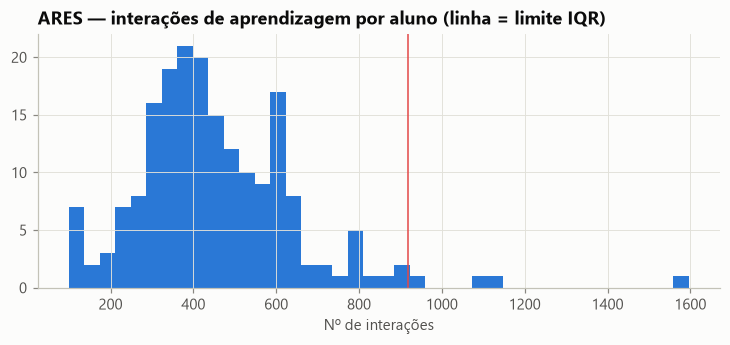

In [16]:
q1, q3 = df["n_interacoes"].quantile([0.25, 0.75])
lim = q3 + 1.5 * (q3 - q1)
df["outlier_interacoes"] = df["n_interacoes"] > lim
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, limite = {lim:.0f} → {df['outlier_interacoes'].sum()} alunos acima")
print("Máximo de interações:", int(df["n_interacoes"].max()))

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(df["n_interacoes"], bins=40, color="#2a78d6")
ax.axvline(lim, color="#e34948", lw=1)
ax.set_title("ARES — interações de aprendizagem por aluno (linha = limite IQR)")
ax.set_xlabel("Nº de interações")
plt.show()

Os outliers **não são removidos**: são comportamentos reais. Todas as análises usam estatística baseada em **postos** (Spearman, Kruskal-Wallis), que é robusta a valores extremos. A distribuição é muito assimétrica, o que justifica o Spearman no notebook 04.

## 8. Base final e conferência com o arquivo oficial

In [17]:
base = {
    "alunos válidos": len(df),
    "com pré": df["nota_pre"].notna().sum(), "com pós": df["nota_pos"].notna().sum(),
    "com pré e pós": df[["nota_pre", "nota_pos"]].notna().all(axis=1).sum(),
    "com log de interação": df["tem_log"].sum(),
    "com pré + pós + log (análises de desempenho)": (df[["nota_pre", "nota_pos"]].notna().all(axis=1) & (df["n_interacoes"] > 0)).sum(),
    "outliers (IQR)": df["outlier_interacoes"].sum(),
}
pd.Series(base, name="alunos").to_frame()

,alunos
alunos válidos,192
com pré,185
com pós,148
com pré e pós,141
com log de interação,192
com pré + pós + log (análises de desempenho),141
outliers (IQR),4


In [18]:
oficial = pd.read_csv(C.PROCESSED / "ares_alunos.csv").set_index("user_id").sort_index()
meu = df.set_index("user_id").sort_index()
cols = list(oficial.columns)
igual = all(np.allclose(oficial[c].astype(float), meu[c].astype(float), equal_nan=True) if oficial[c].dtype != object
            else oficial[c].fillna("").equals(meu[c].fillna("")) for c in cols if c in meu)
print(f"Colunas comparadas: {len(cols)} | alunos: {len(oficial)} × {len(meu)}")
print("✅ Idêntico ao arquivo oficial data/processed/ares_alunos.csv" if igual else "❌ DIVERGE do arquivo oficial")
assert igual

Colunas comparadas: 39 | alunos: 192 × 192
✅ Idêntico ao arquivo oficial data/processed/ares_alunos.csv


**Resultado:** 192 alunos válidos, **141 com pré-teste, pós-teste e log**, que são a base das análises de desempenho (Q1, Q5, Q10). Os 192 entram nas análises de uso (Q4, Q10).

**Próximo:** `03_preparacao_EdNet.ipynb`.